# 07 — Monthly revenue forecast

**Question:** what revenue should the business plan for over the next six months, and how uncertain is that?

**Data:** delivered-order merchandise revenue (sum of item price) by purchase month, 2017-01 → 2018-08 (20 months). Earlier and later months are partial and excluded.

**Model choice.** With only 20 monthly points, a seasonal model (SARIMA, Prophet with yearly seasonality) cannot estimate a 12-month cycle — you need at least two full cycles. We therefore compare three *non-seasonal* candidates on a 3-month hold-out and keep the one with the lowest MAPE, against a naive "last-3-month average" benchmark:
- **Simple exponential smoothing (level only)** — assumes the series has plateaued and forecasts the smoothed current level.
- **Holt's linear trend (damped)** — exponential smoothing with a trend that flattens out.
- **ARIMA(1,1,1) with drift** — a standard differenced autoregressive model.

All are from `statsmodels`, all explainable in one sentence, none needs a seasonal component we cannot support. The Black-Friday spike in Nov 2017 is left in the data (it is real) but flagged. A model that cannot beat the naive benchmark is not worth deploying — that outcome is reported, not hidden.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import warnings; warnings.filterwarnings("ignore")
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from viz_style import *

P = Path("../data/processed")
orders = pd.read_csv(P / "orders.csv", parse_dates=["order_purchase_timestamp"])
items  = pd.read_csv(P / "order_items.csv")

rev = (items.merge(orders.loc[orders.is_delivered, ["order_id", "order_purchase_timestamp"]], on="order_id")
            .assign(month=lambda d: d.order_purchase_timestamp.dt.to_period("M").dt.to_timestamp())
            .groupby("month").price.sum())
rev = rev.loc["2017-01-01":"2018-08-01"]; rev.index.freq = "MS"
print(f"{len(rev)} months, total R${rev.sum()/1e6:.2f}M, last month R${rev.iloc[-1]/1e3:,.0f}k")
rev.round(0).to_frame("revenue").T

20 months, total R$13.18M, last month R$839k


month,2017-01-01,2017-02-01,2017-03-01,2017-04-01,2017-05-01,2017-06-01,2017-07-01,2017-08-01,2017-09-01,2017-10-01,2017-11-01,2017-12-01,2018-01-01,2018-02-01,2018-03-01,2018-04-01,2018-05-01,2018-06-01,2018-07-01,2018-08-01
revenue,111798.0,234223.0,359199.0,340670.0,489338.0,421923.0,481605.0,554700.0,607400.0,648248.0,987765.0,726033.0,924645.0,826437.0,953356.0,973534.0,977545.0,856078.0,867953.0,838577.0


## 1. Trend and seasonality

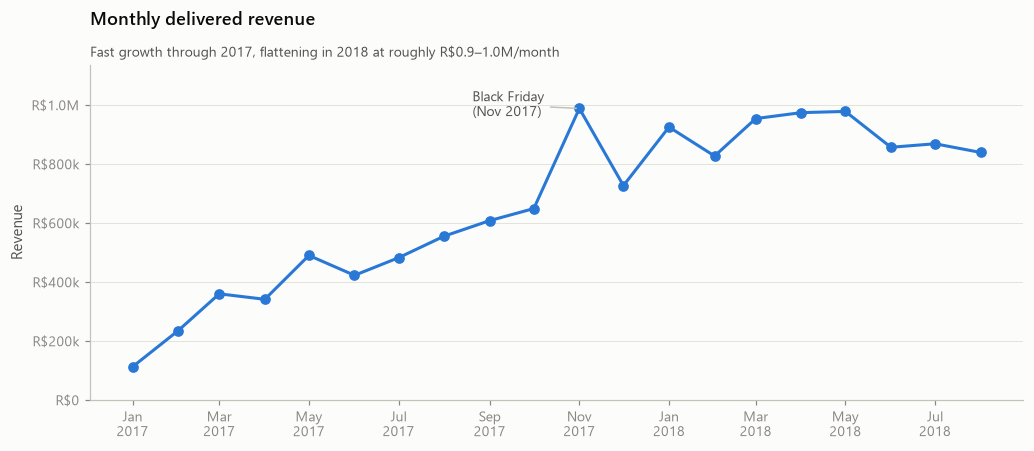

2017: Jan -> Dec x6.5. 2018 H1 month-on-month growth averaged -1.0% with std 11.2pp — growth has stalled.


In [2]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(rev.index, rev.values, marker="o", color=BLUE)
ax.annotate("Black Friday\n(Nov 2017)", (pd.Timestamp("2017-11-01"), rev["2017-11-01"]), textcoords="offset points", xytext=(-70, -5), fontsize=9, color=INK2,
            arrowprops=dict(arrowstyle="-", color=AXIS))
ax.yaxis.set_major_formatter(FuncFormatter(fmt_brl)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_ylim(0, rev.max() * 1.15)
finish(ax, "Monthly delivered revenue", "Fast growth through 2017, flattening in 2018 at roughly R$0.9–1.0M/month", ylabel="Revenue")
plt.tight_layout(); save(fig, "07_revenue_history"); plt.show()

growth_2017 = rev["2017-12-01"] / rev["2017-01-01"]
h1_2018 = rev["2018-01-01":"2018-06-01"]
print(f"2017: Jan -> Dec x{growth_2017:.1f}. 2018 H1 month-on-month growth averaged {100*h1_2018.pct_change().mean():.1f}% with std {100*h1_2018.pct_change().std():.1f}pp — growth has stalled.")

## 2. Hold-out test (last 3 months)

In [3]:
train, test = rev.iloc[:-3], rev.iloc[-3:]
mape = lambda y, yhat: 100 * np.mean(np.abs((y - yhat) / y))

MODELS = {
    "ses_level":       lambda y: ExponentialSmoothing(y, trend=None, seasonal=None).fit(optimized=True),
    "holt_damped":     lambda y: ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal=None).fit(optimized=True),
    "arima_111_drift": lambda y: ARIMA(y, order=(1, 1, 1), trend="t").fit(),
}
results = pd.DataFrame({"actual": test})
for name, fit in MODELS.items():
    results[name] = fit(train).forecast(3).values
results["naive_3m_avg"] = train.iloc[-3:].mean()          # benchmark, not a candidate

scores = {c: mape(test, results[c]) for c in results.columns[1:]}
display(results.round(0))
print("Hold-out MAPE:", {k: f"{v:.1f}%" for k, v in scores.items()})
best = min(MODELS, key=lambda m: scores[m])
print(f"Selected model: {best} ({scores[best]:.1f}% MAPE)",
      "— beats the naive benchmark" if scores[best] < scores["naive_3m_avg"] else "— does NOT beat the naive benchmark; treat the forecast as a flat run-rate")

,actual,ses_level,holt_damped,arima_111_drift,naive_3m_avg
month,,,,,
2018-06-01,856078.0,972663.0,1061369.0,1075869.0,968145.0
2018-07-01,867953.0,972663.0,1101958.0,1104321.0,968145.0
2018-08-01,838577.0,972663.0,1141507.0,1173318.0,968145.0


Hold-out MAPE: {'ses_level': '13.9%', 'holt_damped': '29.0%', 'arima_111_drift': '30.9%', 'naive_3m_avg': '13.4%'}
Selected model: ses_level (13.9% MAPE) — does NOT beat the naive benchmark; treat the forecast as a flat run-rate


**Reading the hold-out.** A naive "average of the last three months" is a deliberately tough benchmark for a flat series. The selected model has to beat it to be worth using; if it only ties, the honest conclusion is "plan on a flat run-rate".

## 3. Six-month forecast with uncertainty

In [4]:
H = 6
future_idx = pd.date_range(rev.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")

model = MODELS[best](rev)                       # refit on the full history
fc = pd.Series(model.forecast(H).values, index=future_idx)
if best.startswith("arima"):
    ci = model.get_forecast(H).conf_int(alpha=0.2); lo, hi = ci.iloc[:, 0].values, ci.iloc[:, 1].values
else:
    sim = model.simulate(H, repetitions=2000, error="add", random_state=42)
    lo, hi = sim.quantile(0.1, axis=1).values, sim.quantile(0.9, axis=1).values
label = {"ses_level": "Exponential smoothing (level)", "holt_damped": "Holt damped-trend", "arima_111_drift": "ARIMA(1,1,1)+drift"}[best]

forecast = pd.DataFrame({"forecast": fc, "lower_80": lo, "upper_80": hi}).round(0)
print(f"{label}: next-6-month total R${fc.sum()/1e6:.2f}M (80% band R${lo.sum()/1e6:.2f}M – R${hi.sum()/1e6:.2f}M)")
forecast

Exponential smoothing (level): next-6-month total R$5.09M (80% band R$3.63M – R$6.57M)


,forecast,lower_80,upper_80
2018-09-01,848167.0,691697.0,1016971.0
2018-10-01,848167.0,645678.0,1050550.0
2018-11-01,848167.0,612609.0,1082083.0
2018-12-01,848167.0,585893.0,1120509.0
2019-01-01,848167.0,562681.0,1137363.0
2019-02-01,848167.0,535797.0,1161122.0


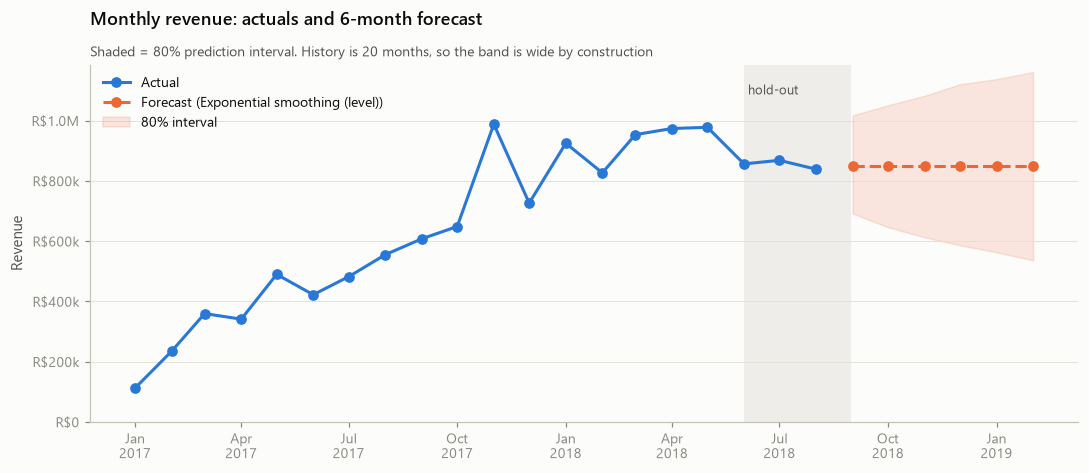

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(rev.index, rev.values, marker="o", color=BLUE, label="Actual")
ax.plot(fc.index, fc.values, marker="o", color=ORANGE, ls="--", label=f"Forecast ({label})")
ax.fill_between(fc.index, lo, hi, color=ORANGE, alpha=0.15, label="80% interval")
ax.axvspan(test.index[0], test.index[-1] + pd.offsets.MonthEnd(0), color=GRID, alpha=0.5, lw=0); ax.text(test.index[0], rev.max()*1.1, " hold-out", fontsize=8.5, color=INK2)
ax.yaxis.set_major_formatter(FuncFormatter(fmt_brl)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_ylim(0, rev.max() * 1.2); ax.legend(loc="upper left")
finish(ax, "Monthly revenue: actuals and 6-month forecast", "Shaded = 80% prediction interval. History is 20 months, so the band is wide by construction", ylabel="Revenue")
plt.tight_layout(); save(fig, "07_forecast"); plt.show()

In [6]:
out = pd.concat([rev.rename("actual").to_frame().assign(type="actual"),
                 forecast.assign(type="forecast")]).reset_index().rename(columns={"index": "month"})
out["month"] = out.month.dt.strftime("%Y-%m-01")
out.to_csv(P / "revenue_forecast.csv", index=False)
pd.Series(scores).round(2).to_frame("holdout_mape_pct").to_csv(P / "forecast_model_scores.csv")
print("exported revenue_forecast.csv and forecast_model_scores.csv")

exported revenue_forecast.csv and forecast_model_scores.csv


## So what

- **Growth has plateaued.** Revenue grew 6.5× across 2017 and then flattened at R$0.85–1.0M a month in 2018 (H1 2018 month-on-month growth averaged −1%). Trend models that extrapolate 2017 overshoot the hold-out by ~30%; the level-only model wins, so the forecast is the current run-rate, not a continuation of 2017's climb.
- **Plan on the run-rate, budget for the band.** With 20 months of history the 80% interval is wide; the right use of this forecast is a planning baseline and an early-warning line — if actuals fall below the lower band for two months, something structural has changed.
- **Seasonality is real but unmodellable yet.** Nov 2017 (Black Friday) was ~50% above trend. Expect a similar spike in Nov 2018 that this model does *not* predict; add it as a manual overlay until there are 24+ months of data.

**Limitations, honestly:** short history (20 points), a marketplace in its growth phase (the data-generating process itself is changing), no external regressors (marketing spend, partner onboarding), and revenue is measured at *purchase* month for *delivered* orders — the last few months are slightly understated because some orders placed then were still in transit when the snapshot was taken.